# Otimização de corte na rebobinadeira — demonstração

**Problema:** a bobina-mãe chega com uma largura fixa (ex.: 500 mm) e os clientes pedem bobinas-filhas de várias larguras (75, 90, 110 mm...). Cortar cada largura separadamente gera muita **apara** (perda).

**Método:** gerar todos os padrões de corte possíveis (respeitando a largura e as 17 facas) e usar **Programação Linear Inteira** para escolher quantas bobinas cortar com cada padrão.

**Dados:** os pedidos abaixo são **fictícios**.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))  # para importar o pacote a partir de notebooks/

import pandas as pd
import matplotlib.pyplot as plt
from otimizador_corte import Configuracao, ler_pedidos_csv, otimizar, formatar_resultado

## 1. Pedidos de exemplo

In [2]:
pedidos = ler_pedidos_csv('../dados/pedidos_exemplo.csv')
pd.DataFrame([vars(p) for p in pedidos])

,largura_mm,quantidade,cliente
0,75,120,Cliente A (fictício)
1,70,90,Cliente B (fictício)
2,90,80,Cliente C (fictício)
3,110,45,Cliente D (fictício)
4,75,30,Cliente E (fictício)
5,140,25,Cliente F (fictício)
6,60,60,Cliente G (fictício)


## 2. O caso simples: só 75 mm

Bobina de 500 mm → 6 tiras de 75 mm = 450 mm, sobram **50 mm de apara (10%)** em toda bobina.

In [3]:
from otimizador_corte import Pedido
cfg = Configuracao(largura_bobina_mm=500, facas=17)
r = otimizar([Pedido(75, 60)], cfg)
print(r.bobinas_mae, 'bobinas, perda de', round(r.perda_percentual, 1), '%')

10 bobinas, perda de 10.0 %


## 3. Otimizando todos os pedidos juntos

Misturar larguras na mesma bobina aproveita a sobra. Refile de 5 mm por borda.

In [4]:
cfg = Configuracao(largura_bobina_mm=500, facas=17, refile_mm=5)
res = otimizar(pedidos, cfg)
print(formatar_resultado(res, cfg))

 PLANO DE CORTE — REBOBINADEIRA
 Bobinas-mãe disponíveis: 500 mm | Facas: 17 (máx. 16 tiras)
 Refile mínimo: 5 mm/borda | Status do solver: ótimo

 Padrão 1: cortar 17 bobina(s) de 500 mm
   Tiras:  3 x 90 + 2 x 75 + 1 x 70  (6 tiras)
   Apara:  10 mm por bobina (refile + sobra)
   Facas (7) em mm: [5, 95, 185, 275, 350, 425, 495]
   |░|   90   |   90   |   90   |  75  |  75  |  70  |░|

 Padrão 2: cortar 12 bobina(s) de 500 mm
   Tiras:  1 x 140 + 2 x 75 + 2 x 70 + 1 x 60  (6 tiras)
   Apara:  10 mm por bobina (refile + sobra)
   Facas (7) em mm: [5, 145, 220, 295, 365, 435, 495]
   |░|     140     |  75  |  75  |  70  |  70  |  60 |░|

 Padrão 3: cortar 8 bobina(s) de 500 mm
   Tiras:  1 x 140 + 1 x 110 + 2 x 90 + 1 x 60  (5 tiras)
   Apara:  10 mm por bobina (refile + sobra)
   Facas (6) em mm: [5, 145, 255, 345, 435, 495]
   |░|     140     |   110    |   90   |   90   |  60 |░|

 Padrão 4: cortar 6 bobina(s) de 500 mm
   Tiras:  2 x 110 + 2 x 75 + 2 x 60  (6 tiras)
   Apara:  10 m

## 4. Visualizando os padrões de corte

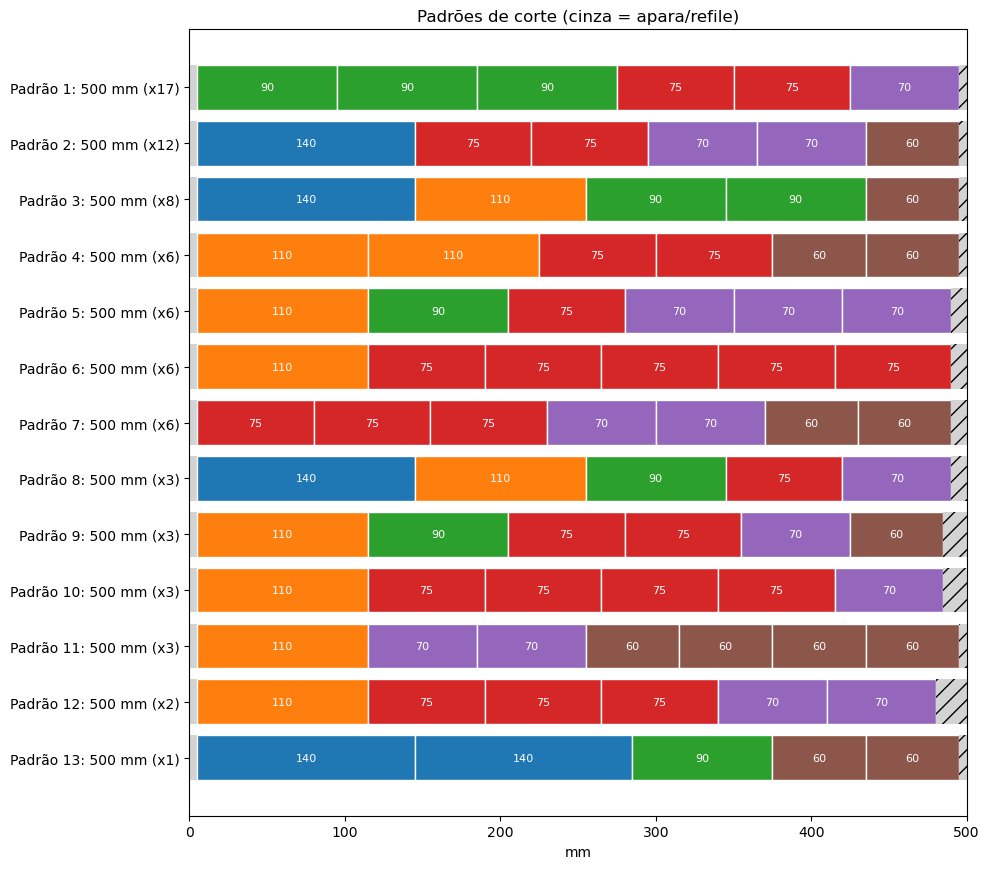

In [5]:
def desenhar(res, cfg):
    fig, ax = plt.subplots(figsize=(10, 0.6 * len(res.planos) + 1))
    cores = plt.cm.tab10.colors
    larguras = sorted({w for p in res.planos for w in p.padrao}, reverse=True)
    cor = {w: cores[i % 10] for i, w in enumerate(larguras)}
    for i, p in enumerate(res.planos):
        x = 0
        ax.barh(i, cfg.refile_mm, left=x, color='lightgray'); x += cfg.refile_mm
        for w, k in sorted(p.padrao.items(), reverse=True):
            for _ in range(k):
                ax.barh(i, w, left=x, color=cor[w], edgecolor='white')
                ax.text(x + w / 2, i, str(w), ha='center', va='center', fontsize=8, color='white')
                x += w
        ax.barh(i, p.largura_bobina_mm - x, left=x, color='lightgray', hatch='//')
    ax.set_yticks(range(len(res.planos)))
    ax.set_yticklabels([f'Padrão {i+1}: {p.largura_bobina_mm} mm (x{p.repeticoes})' for i, p in enumerate(res.planos)])
    ax.invert_yaxis(); ax.set_xlim(0, max(cfg.larguras_bobina)); ax.set_xlabel('mm')
    ax.set_title('Padrões de corte (cinza = apara/refile)')
    plt.tight_layout(); plt.show()

desenhar(res, cfg)

## 5. Corte simples × otimizado

In [6]:
c = res.comparacao
df = pd.DataFrame({
    'Bobinas-mãe': [c['simples_bobinas'], c['otimizado_bobinas']],
    'Papel (mm)': [c['simples_material_mm'], c['otimizado_material_mm']],
    'Perda (%)': [round(c['simples_perda_pct'], 2), round(c['otimizado_perda_pct'], 2)],
}, index=['Corte simples', 'Otimizado'])
df

,Bobinas-mãe,Papel (mm),Perda (%)
Corte simples,83,41500,9.11
Otimizado,76,38000,2.51


## 6. Bobinas-mãe de 500 a 1100 mm

A largura da bobina-mãe varia. Passando uma lista, o modelo escolhe qual largura usar em cada padrão. Aqui o refile mínimo é de 8 mm por borda (ele depende do ajuste das facas).

melhor solução em 30s, no máximo 0.3% acima do ótimo
Bobinas usadas: {1100: 33, 800: 1, 500: 1}
Perda: 1.89 %


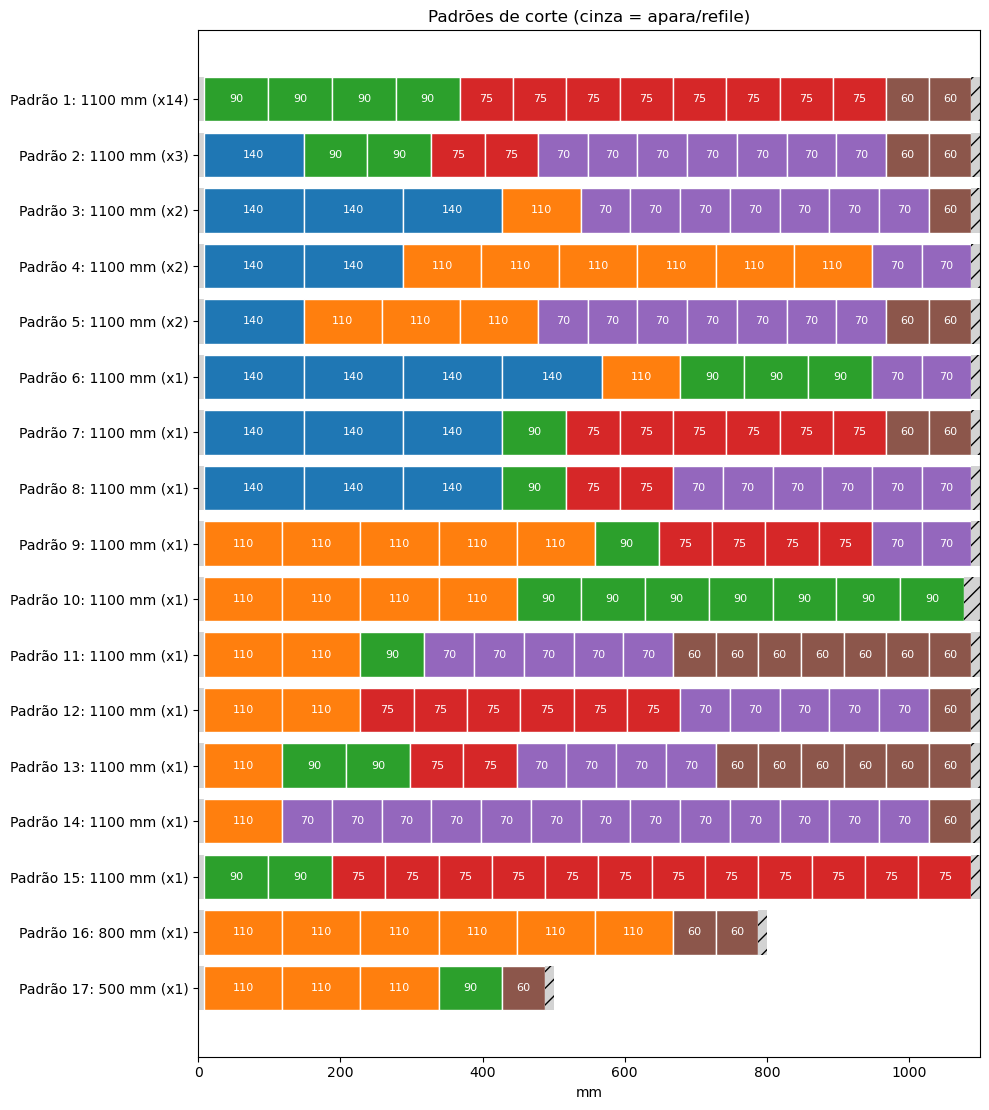

In [7]:
cfg_var = Configuracao(largura_bobina_mm=[500, 800, 1100], facas=17, refile_mm=8)
res_var = otimizar(pedidos, cfg_var)
print(res_var.status)
print('Bobinas usadas:', res_var.bobinas_por_largura)
print('Perda:', round(res_var.perda_percentual, 2), '%')
desenhar(res_var, cfg_var)

## 7. Menos trocas de faca

Trocar as facas leva tempo. Com `custo_troca`, cada padrão novo "custa" uma fração de bobina, e o modelo prefere usar menos padrões.

In [8]:
linhas = []
for custo in [0, 0.25, 0.5, 1]:
    r = otimizar(pedidos, Configuracao(largura_bobina_mm=1100, refile_mm=8, custo_troca=custo))
    linhas.append({'custo_troca': custo, 'bobinas': r.bobinas_mae,
                   'trocas de faca': r.trocas_de_faca, 'papel (mm)': r.material_mm, 'perda %': round(r.perda_percentual, 2)})
pd.DataFrame(linhas)

,custo_troca,bobinas,trocas de faca,papel (mm),perda %
0,0.00,35,7,38500,1.82
1,0.25,35,3,38500,1.82
2,0.50,35,3,38500,1.82
3,1.00,35,2,38500,1.82
